## Hydrodynamic model of the Southern North Sea

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import mikeio
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import modelskill as ms
import torch

# dataset helper
from helper import get_altimetry_obs, get_wl_point_obs
from helper import plot_shred_reconstruction, extract_water_level_measurements

import sys
from pathlib import Path

# Add parent directory to path to access src module
sys.path.insert(0, str(Path.cwd().parent.parent))

# Importing modules from src
from src.datamanager import DataManager
from src.engine import SHREDEngine
from src.train import fit, evaluate
from src.mSHRED.mSHRED import mSHRED
from src.utils import plot_training_curves, evaluate_model

# get device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

## Load Data and Measurement

Extracted measurements for station Drogden from datasets/observations/Drogden_wl.csv
Extracted measurements for station Klagshamn from datasets/observations/Klagshamn_wl.csv
Extracted measurements for station Barseback from datasets/observations/Barseback_wl.csv
Extracted measurements for station Dragor from datasets/observations/Dragor_wl.csv


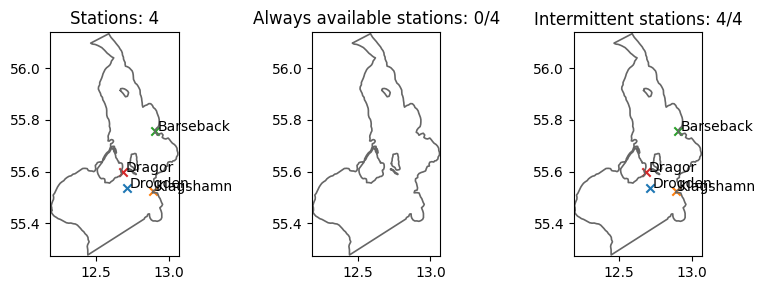

In [ ]:
import gc

# folders
dfs_fldr = "datasets/output/Area.dfsu"
msh_fldr = "datasets/input/mesh_EMOD.mesh"
obs_fldr  = "datasets/observations/"

msh = mikeio.open(msh_fldr)
dfs = mikeio.open(dfs_fldr)
geom = dfs.geometry

# read datasets once and release the full object immediately afterwards
ds = dfs.read()

# sensor coverage
alllist = get_wl_point_obs()

# For sparse data simulation
hf = ["Drogden", "Klagshamn", "Dragor", "Barseback"]
# availabilities 97-50-98-50
alllist = [s for s in alllist if s.name in hf]

stations = []
available_stations = []
intermittent = []
for i in range(len(alllist)):
    stations.append(alllist[i])
    if ds.time.isin(alllist[i].time).all():
        available_stations.append(alllist[i])
    else:
        intermittent.append(alllist[i])

# extract water level measurements for all stations
measurements = extract_water_level_measurements(stations, ds_time=ds.time, obs_fldr=obs_fldr)

fig, axs = plt.subplots(1,3, figsize=(8,3))
ms.plotting.spatial_overview(stations, mod=msh.geometry, figsize=(5,5), ax=axs[0], title=f"Stations: {len(stations)}")
ms.plotting.spatial_overview(available_stations, mod=msh.geometry, figsize=(5,5), ax=axs[1], title=f"Always available stations: {len(available_stations)}/{len(stations)}")
ms.plotting.spatial_overview(intermittent, mod=msh.geometry, figsize=(5,5), ax=axs[2], title=f"Intermittent stations: {len(intermittent)}/{len(stations)}")
plt.tight_layout()
plt.show()

# materialize only the variables needed downstream
H_all = ds["Surface elevation"].to_numpy()
U_all = ds["U velocity"].to_numpy()
V_all = ds["V velocity"].to_numpy()

# remove nans from H, U, V using the same mask for all fields
valid = ~np.isnan(H_all).any(axis=0)
H = torch.from_numpy(np.ascontiguousarray(H_all[:, valid].astype(np.float32, copy=False)))
U = torch.from_numpy(np.ascontiguousarray(U_all[:, valid].astype(np.float32, copy=False)))
V = torch.from_numpy(np.ascontiguousarray(V_all[:, valid].astype(np.float32, copy=False)))

# inputs
measurements = torch.tensor(np.asarray(measurements, dtype=np.float32), dtype=torch.float32)

# print the shape of the arrays
print("H shape:", H.shape)
print("U shape:", U.shape)
print("V shape:", V.shape)
print("Measurements shape:", measurements.shape)

# free memory aggressively: keep only the tensors required downstream
del dfs, ds, msh, geom, alllist, hf, stations, available_stations, intermittent, H_all, U_all, V_all, valid
gc.collect()

In [ ]:
ERRORS = []

# DataManager
LAGS = 24

TRAIN_SIZE = 0.8        # percentage of data used for training 
VAL_SIZE = 0.1          # percentage of data used for validation
TEST_SIZE = 0.1         # percentage of data used for testing

COMPRESS_H = 12         # modes kept for H (surface elevation)
COMPRESS_U = 40         # modes kept for U (U velocity)
COMPRESS_V = 68         # modes kept for V (V velocity)

# Training
OPTIMIZER = "AdamW"     # optimizer to use
LEARNING_RATE = 1e-3    # learning rate for training
NUM_EPOCHS = 200        # maximum number of epochs for training
LR_SCHEDULER = "CosineAnnealingLR"      # learning rate scheduler to use
SCHEDULER_STEP_SIZE = NUM_EPOCHS        # step size for learning rate scheduler (if applicable)

BATCH_SIZE = 32         # batch size for training
PATIENCE = 40           # number of epochs with no improvement on validation loss before stopping training
VERBOSE_TRAIN = True

# Architecture
ENCODER_DEPTH = 2              # number of encoder layers
HIDDEN_SIZE = 32                # hidden size for encoder and decoder layers
N_HEADS = 4                     # number of attention heads (if using a transformer-based architecture)
DIM_FEEDFORWARD = 48            # dimension of feedforward network in transformer (if using a transformer-based architecture)
DECODER = "cnn"                 # type of decoder to use (mpl or cnn)   
DECODER_HIDDEN_SIZES = [64]     # hidden sizes for decoder layers 
DROPOUT = 0.0                   # dropout rate for encoder and decoder layers
MASKING_TYPE = "mask_data"      # type of masking to apply to inputs during training (mask_data, mask_data_random, etc.)

## Always available strategy -> not applicable

## (T.1.A): Median imputer

In [ ]:
# Data manager
manager = DataManager(lags=LAGS, train_size=TRAIN_SIZE, val_size=VAL_SIZE, test_size=TEST_SIZE)
# add data to manager
manager.add_data(H, id="Surface elevation", compress=COMPRESS_H, measurements=measurements, imputer="median")
manager.add_data(U, id="U velocity", compress=COMPRESS_U)
manager.add_data(V, id="V velocity", compress=COMPRESS_V)
# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare(verbose=True)

# network input and output shapes
nn_input_shape = train_dataset[0][0].shape[1]
nn_output_shape = train_dataset[0][1].shape[0]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)

In [ ]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels=False,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT,
)
mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
)

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshred, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): TR+{DECODER}", type="(T.1.A): median imputation for missing sensors"
 )

ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

In [ ]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="(T.1.A)_median_imputation")

del engine, test_reconstruction, ds_shred, ds_error, mshred, manager, train_dataset, val_dataset, test_dataset, model_args, train_errors, valid_errors, test_error, nn_input_shape, nn_output_shape

## (T.1.B): Mean imputer

In [ ]:
# Data manager
manager = DataManager(lags=LAGS, train_size=TRAIN_SIZE, val_size=VAL_SIZE, test_size=TEST_SIZE)
# add data to manager
manager.add_data(H, id="Surface elevation", compress=COMPRESS_H, measurements=measurements, imputer="mean")
manager.add_data(U, id="U velocity", compress=COMPRESS_U)
manager.add_data(V, id="V velocity", compress=COMPRESS_V)
# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare(verbose=True)

# network input and output shapes
nn_input_shape = train_dataset[0][0].shape[1]
nn_output_shape = train_dataset[0][1].shape[0]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)

In [ ]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels=False,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT,
)
mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
)

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshred, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): TR+{DECODER}", type="(T.1.B): mean imputation for missing sensors"
 )

ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

In [ ]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="(T.1.B)_mean_imputation")

del engine, test_reconstruction, ds_shred, ds_error, mshred, manager, train_dataset, val_dataset, test_dataset, model_args, train_errors, valid_errors, test_error, nn_input_shape, nn_output_shape

## (T.1.C): Last value imputer

In [ ]:
# Data manager
manager = DataManager(lags=LAGS, train_size=TRAIN_SIZE, val_size=VAL_SIZE, test_size=TEST_SIZE)
# add data to manager
manager.add_data(H, id="Surface elevation", compress=COMPRESS_H, measurements=measurements, imputer="last_value")
manager.add_data(U, id="U velocity", compress=COMPRESS_U)
manager.add_data(V, id="V velocity", compress=COMPRESS_V)
# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare(verbose=True)

# network input and output shapes
nn_input_shape = train_dataset[0][0].shape[1]
nn_output_shape = train_dataset[0][1].shape[0]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)

In [ ]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels=False,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT,
)
mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
)

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshred, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): TR+{DECODER}", type="(T.1.C): last-value imputation for missing sensors"
 )

ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

In [ ]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="(T.1.C)_last_value_imputation")

del engine, test_reconstruction, ds_shred, ds_error, mshred, manager, train_dataset, val_dataset, test_dataset, model_args, train_errors, valid_errors, test_error, nn_input_shape, nn_output_shape

## (T.2.A) GRUD

In [ ]:
# Data manager
manager = DataManager(lags=LAGS, train_size=TRAIN_SIZE, val_size=VAL_SIZE, test_size=TEST_SIZE)
# add data to manager
manager.add_data(H, id="Surface elevation", compress=COMPRESS_H, measurements=measurements)
manager.add_data(U, id="U velocity", compress=COMPRESS_U)
manager.add_data(V, id="V velocity", compress=COMPRESS_V)
# prepare datasets
train_dataset, val_dataset, test_dataset, X_mean = manager.prepare(verbose=True, masking_type="grud")

# network input and output shapes
nn_input_shape = train_dataset[0][0].shape[-1]
nn_output_shape = train_dataset[0][1].shape[0]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)

In [ ]:
# GRUD TRAINING
model_args = dict(
    # Encoder
    encoder="grud", input_size=nn_input_shape, hidden_size=HIDDEN_SIZE, X_mean=X_mean,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT,
)
mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
)

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshred, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): GRUD+{DECODER}", type="(T.2.A): GRUD"
 )

ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

In [ ]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_grud, ds_error_grud = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="(T.2.A)_GRUD")

del engine, test_reconstruction, ds_grud, ds_error_grud, mshred, model_args, train_errors, valid_errors, test_error

## (T.2.B): Attn-GRUD

In [ ]:
# Attn-GRUD TRAINING
model_args = dict(
    # Encoder
    encoder="att_grud", input_size=nn_input_shape, hidden_size=HIDDEN_SIZE, X_mean=X_mean,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT,
)
mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
)

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshred, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): Attn-GRUD+{DECODER}", type="(T.2.B): Attn-GRUD"
 )

ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

In [ ]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_grud, ds_error_grud = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="(T.2.B)_Attn-GRUD")

del engine, test_reconstruction, ds_grud, ds_error_grud, mshred, manager, train_dataset, val_dataset, test_dataset, model_args, train_errors, valid_errors, test_error, nn_input_shape, nn_output_shape, X_mean

## (T.3.A): Masking

In [ ]:
# Data manager
manager = DataManager(lags=LAGS, train_size=TRAIN_SIZE, val_size=VAL_SIZE, test_size=TEST_SIZE)
# add data to manager
manager.add_data(H, id="Surface elevation", compress=COMPRESS_H, measurements=measurements)
manager.add_data(U, id="U velocity", compress=COMPRESS_U)
manager.add_data(V, id="V velocity", compress=COMPRESS_V)
# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare(verbose=True, masking_type=MASKING_TYPE)

# network input and output shapes
nn_input_shape = train_dataset.X.shape[-1]
nn_output_shape = train_dataset.Y.shape[-1]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)

In [ ]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels=False,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT, 
)
mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
    masking_type=MASKING_TYPE,
)

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshred, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): TR+{DECODER}", type="(T.3.A): masking", masking_type=MASKING_TYPE
)

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

In [ ]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="(T.3.A)_masking")

del engine, test_reconstruction, ds_shred, ds_error, mshred, model_args, train_errors, valid_errors, test_error

## (T.3.B): Masking x2 channels

In [ ]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels=True,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT, 
 )
mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
    masking_type=MASKING_TYPE,
 )

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshred, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): TR+{DECODER}", type="(T.3.B): masking x2 channels", masking_type=MASKING_TYPE
 )

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

In [ ]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="(T.3.B)_masking_x2_channels")

del engine, test_reconstruction, ds_shred, ds_error, mshred, model_args, train_errors, valid_errors, test_error

## (T.3.C): Masking hidden space

In [ ]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_hidden_mask", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT, 
 )
mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
    masking_type=MASKING_TYPE,
 )

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshred, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): TR+{DECODER}", type="(T.3.C): masking hidden space", masking_type=MASKING_TYPE
 )

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

In [ ]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="(T.3.C)_masking_hidden_space")

del engine, test_reconstruction, ds_shred, ds_error, mshred, model_args, train_errors, valid_errors, test_error

## (T.3.D): Masking MHSA

In [ ]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_attn_mask", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels=False,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT, 
 )
mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
    masking_type=MASKING_TYPE,
 )

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshred, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): TR+{DECODER}", type="(T.3.D): masking MHSA", masking_type=MASKING_TYPE
 )

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

In [ ]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="(T.3.D)_masking_MHSA")

del engine, test_reconstruction, ds_shred, ds_error, mshred, model_args, train_errors, valid_errors, test_error

## (T.3.E): Masking x2 channels + MHSA

In [ ]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_attn_mask", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels=True,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT, 
 )
mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
    masking_type=MASKING_TYPE,
 )

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshred, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): TR+{DECODER}", type="(T.3.E): masking x2 channels + MHSA", masking_type=MASKING_TYPE
 )

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

In [ ]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="(T.3.E)_masking_x2_channels_MHSA")

del engine, test_reconstruction, ds_shred, ds_error, mshred, model_args, train_errors, valid_errors, test_error

## (T.3.F): Masking MHSA learned

In [ ]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_learned_mask", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT, 
 )
mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
    masking_type=MASKING_TYPE,
 )

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshred, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): TR+{DECODER}", type="(T.3.F): masking MHSA learned", masking_type=MASKING_TYPE
 )

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

In [ ]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="(T.3.F)_masking_MHSA_learned")

del engine, test_reconstruction, ds_shred, ds_error, mshred, model_args, train_errors, valid_errors, test_error

## (T.3.G): Masking x2 channels + MHSA learned

In [ ]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_learned_mask", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels=True,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT, 
 )
mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
    masking_type=MASKING_TYPE,
 )

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshred, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): TR+{DECODER}", type="(T.3.G): masking x2 channels + MHSA learned", masking_type=MASKING_TYPE
 )

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

In [ ]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="(T.3.G)_masking_x2_channels_MHSA_learned")

del engine, test_reconstruction, ds_shred, ds_error, mshred, manager, train_dataset, val_dataset, test_dataset, model_args, train_errors, valid_errors, test_error, nn_input_shape, nn_output_shape

## Results

In [ ]:
dataframe_errors = pd.read_csv("dataframe_errors.csv")  # reload to ensure clean data
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

In [ ]:
# order dataframe by test-mre
print("\nFinal comparison of all models, ordered by test MRE:")
dataframe_errors = dataframe_errors.sort_values(by="test-mre")
display(dataframe_errors)

In [ ]:
# Meaningful summary plot: ranking + improvement vs baseline
df_plot = dataframe_errors.sort_values("test-mre").reset_index(drop=True)

# Baseline = T.0 (only available sensors)
baseline_mask = df_plot["type"].str.contains("T.0", regex=False)
baseline_test_mre = df_plot.loc[baseline_mask, "test-mre"].iloc[0] if baseline_mask.any() else df_plot["test-mre"].max()

# Keep raw values for ratio math, but plot MRE on a 0-100% scale
df_plot["test-mre_%"] = 100 * df_plot["test-mre"]
df_plot["improvement_vs_T0_%"] = 100 * (baseline_test_mre - df_plot["test-mre"]) / baseline_test_mre

fig, axes = plt.subplots(1, 2, figsize=(16, 7), constrained_layout=True)

# --- Left: Test MRE ranking (%) ---
colors = plt.cm.viridis(np.linspace(0.15, 0.9, len(df_plot)))
axes[0].barh(df_plot["type"], df_plot["test-mre_%"], color=colors)
axes[0].invert_yaxis()
axes[0].set_title("Model ranking by Test MRE (lower is better)")
axes[0].set_xlabel("Test MRE (%)")
axes[0].grid(axis="x", alpha=0.3)

for i, v in enumerate(df_plot["test-mre_%"]):
    axes[0].text(v + 0.03, i, f"{v:.2f}%", va="center", fontsize=9)

# --- Right: Improvement vs baseline (T.0) ---
imp_colors = ["tab:green" if x >= 0 else "tab:red" for x in df_plot["improvement_vs_T0_%"]]
axes[1].barh(df_plot["type"], df_plot["improvement_vs_T0_%"], color=imp_colors)
axes[1].invert_yaxis()
axes[1].axvline(0, color="black", linewidth=1)
axes[1].set_title("Relative improvement vs baseline T.0")
axes[1].set_xlabel("Improvement in Test MRE (%)")
axes[1].grid(axis="x", alpha=0.3)

for i, v in enumerate(df_plot["improvement_vs_T0_%"]):
    axes[1].text(v + (0.4 if v >= 0 else -2.5), i, f"{v:.1f}%", va="center", fontsize=9)

plt.show()

## Run1: all sensors, all time

In [ ]:
ERRORS = []

# DataManager
LAGS = 48

TRAIN_SIZE = 0.8        # percentage of data used for training 
VAL_SIZE = 0.1          # percentage of data used for validation
TEST_SIZE = 0.1         # percentage of data used for testing

COMPRESS_H = 12         # modes kept for H (surface elevation)
COMPRESS_U = 40         # modes kept for U (U velocity)
COMPRESS_V = 68         # modes kept for V (V velocity)

# Training
OPTIMIZER = "AdamW"     # optimizer to use
LEARNING_RATE = 1e-3    # learning rate for training
NUM_EPOCHS = 200        # maximum number of epochs for training
LR_SCHEDULER = "CosineAnnealingLR"      # learning rate scheduler to use
SCHEDULER_STEP_SIZE = NUM_EPOCHS        # step size for learning rate scheduler (if applicable)

BATCH_SIZE = 32         # batch size for training
PATIENCE = 50           # number of epochs with no improvement on validation loss before stopping training
VERBOSE_TRAIN = True

# Architecture
ENCODER_DEPTH = 2               # number of encoder layers
HIDDEN_SIZE = 32                # hidden size for encoder and decoder layers
N_HEADS = 4                     # number of attention heads (if using a transformer-based architecture)
DIM_FEEDFORWARD = 64            # dimension of feedforward network in transformer (if using a transformer-based architecture)
DECODER = "mlp"                 # type of decoder to use (mpl or cnn)   
DECODER_HIDDEN_SIZES = [64]     # hidden sizes for decoder layers 
DROPOUT = 0.0                   # dropout rate for encoder and decoder layers
MASKING_TYPE = "mask_data"      # type of masking to apply to inputs during training (mask_data, mask_data_random, etc.)

<div>
<style scoped>
    .dataframe tbody tr th:only-of-type {
        vertical-align: middle;
    }

    .dataframe tbody tr th {
        vertical-align: top;
    }

    .dataframe thead th {
        text-align: right;
    }
</style>
<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>model</th>
      <th>type</th>
      <th>train-mse</th>
      <th>val-mse</th>
      <th>test-mse</th>
      <th>train-mre</th>
      <th>val-mre</th>
      <th>test-mre</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>3</th>
      <td>(mSHRED): TR+mlp</td>
      <td>(T.1.B): mean imputation for missing sensors</td>
      <td>0.003361</td>
      <td>0.003900</td>
      <td>0.009575</td>
      <td>0.117646</td>
      <td>0.122916</td>
      <td>0.192705</td>
    </tr>
    <tr>
      <th>4</th>
      <td>(mSHRED): TR+mlp</td>
      <td>(T.1.C): last-value imputation for missing sen...</td>
      <td>0.003190</td>
      <td>0.003948</td>
      <td>0.009714</td>
      <td>0.114918</td>
      <td>0.123116</td>
      <td>0.193729</td>
    </tr>
    <tr>
      <th>0</th>
      <td>(mSHRED): TR+mlp</td>
      <td>(T.0): always-available stations only</td>
      <td>0.003259</td>
      <td>0.003846</td>
      <td>0.009659</td>
      <td>0.115895</td>
      <td>0.122155</td>
      <td>0.194037</td>
    </tr>
    <tr>
      <th>2</th>
      <td>(mSHRED): TR+mlp</td>
      <td>(T.1.A): median imputation for missing sensors</td>
      <td>0.003169</td>
      <td>0.003877</td>
      <td>0.009679</td>
      <td>0.114575</td>
      <td>0.122569</td>
      <td>0.194251</td>
    </tr>
    <tr>
      <th>1</th>
      <td>(mSHRED): LSTM+mlp</td>
      <td>(S.0): always-available stations only</td>
      <td>0.003473</td>
      <td>0.003928</td>
      <td>0.009773</td>
      <td>0.119093</td>
      <td>0.123326</td>
      <td>0.195167</td>
    </tr>
    <tr>
      <th>11</th>
      <td>(mSHRED): TR+mlp</td>
      <td>(T.3.E): masking x2 channels + MHSA</td>
      <td>0.003189</td>
      <td>0.004057</td>
      <td>0.010050</td>
      <td>0.114991</td>
      <td>0.125845</td>
      <td>0.196136</td>
    </tr>
    <tr>
      <th>13</th>
      <td>(mSHRED): TR+mlp</td>
      <td>(T.3.G): masking x2 channels + MHSA learned</td>
      <td>0.003354</td>
      <td>0.004029</td>
      <td>0.009995</td>
      <td>0.117692</td>
      <td>0.125566</td>
      <td>0.196744</td>
    </tr>
    <tr>
      <th>7</th>
      <td>(mSHRED): TR+mlp</td>
      <td>(T.3.A): masking</td>
      <td>0.003182</td>
      <td>0.004019</td>
      <td>0.010261</td>
      <td>0.114664</td>
      <td>0.125393</td>
      <td>0.197361</td>
    </tr>
    <tr>
      <th>12</th>
      <td>(mSHRED): TR+mlp</td>
      <td>(T.3.F): masking MHSA learned</td>
      <td>0.003409</td>
      <td>0.004061</td>
      <td>0.010111</td>
      <td>0.118281</td>
      <td>0.126204</td>
      <td>0.197436</td>
    </tr>
    <tr>
      <th>8</th>
      <td>(mSHRED): TR+mlp</td>
      <td>(T.3.B): masking x2 channels</td>
      <td>0.003009</td>
      <td>0.004006</td>
      <td>0.010165</td>
      <td>0.111877</td>
      <td>0.124656</td>
      <td>0.198088</td>
    </tr>
    <tr>
      <th>9</th>
      <td>(mSHRED): TR+mlp</td>
      <td>(T.3.C): masking hidden space</td>
      <td>0.003010</td>
      <td>0.004071</td>
      <td>0.010479</td>
      <td>0.111701</td>
      <td>0.125053</td>
      <td>0.200429</td>
    </tr>
    <tr>
      <th>10</th>
      <td>(mSHRED): TR+mlp</td>
      <td>(T.3.D): masking MHSA</td>
      <td>0.003150</td>
      <td>0.003971</td>
      <td>0.010487</td>
      <td>0.114490</td>
      <td>0.124583</td>
      <td>0.201338</td>
    </tr>
    <tr>
      <th>6</th>
      <td>(mSHRED): Attn-GRUD+mlp</td>
      <td>(T.2.B): Attn-GRUD</td>
      <td>0.003526</td>
      <td>0.004567</td>
      <td>0.011375</td>
      <td>0.120008</td>
      <td>0.134351</td>
      <td>0.210642</td>
    </tr>
    <tr>
      <th>5</th>
      <td>(mSHRED): GRUD+mlp</td>
      <td>(T.2.A): GRUD</td>
      <td>0.003163</td>
      <td>0.004664</td>
      <td>0.011444</td>
      <td>0.114303</td>
      <td>0.135929</td>
      <td>0.211484</td>
    </tr>
  </tbody>
</table>
</div>

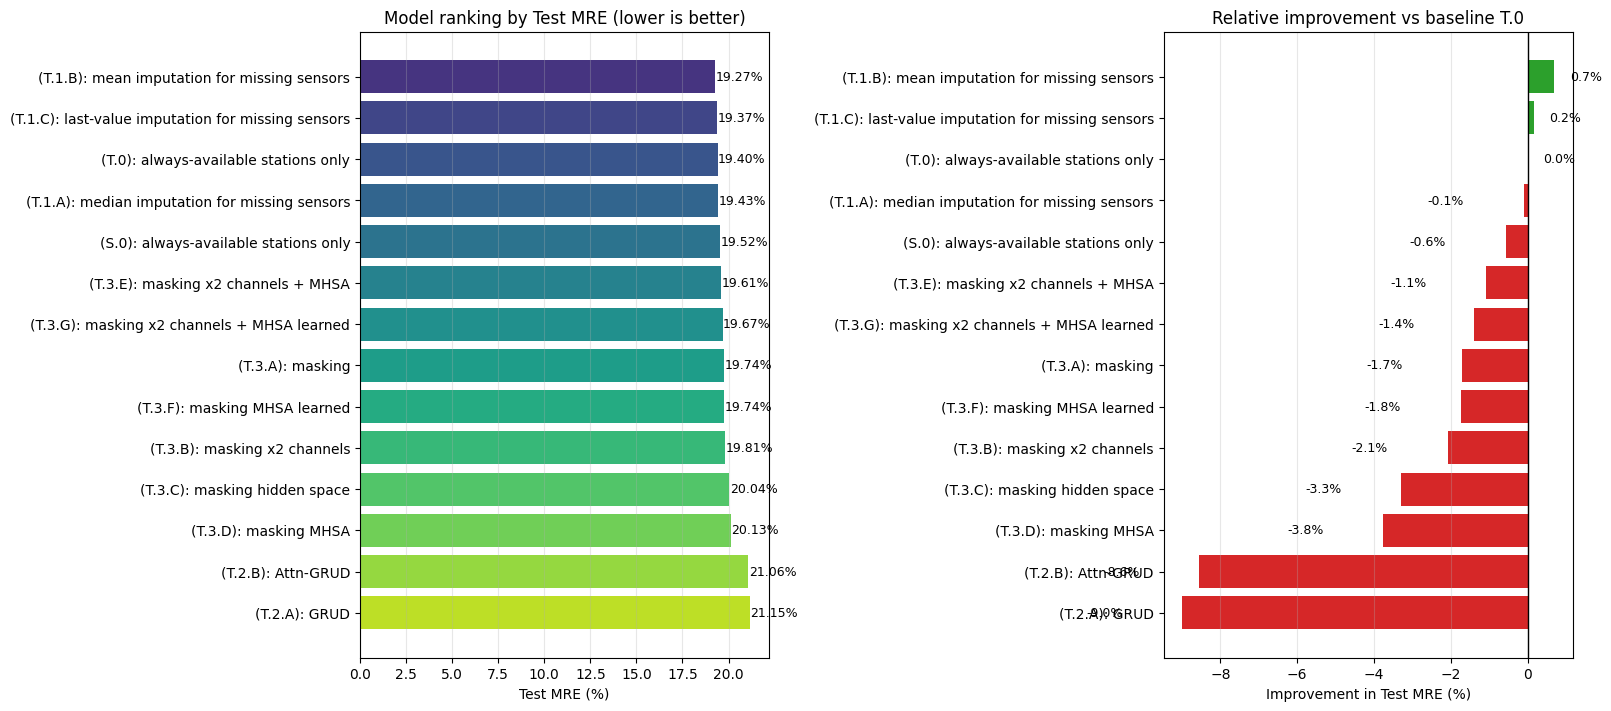

## Run2: high fidelity sensors, less time

ds = dfs.read(time = slice("2022-01-01", "2023-10-30"))

high_fidelity = ["Dover", "ZeebruggeWielingendok", "NWA", "K141"]

In [ ]:
ERRORS = []

# DataManager
LAGS = 48

TRAIN_SIZE = 0.8        # percentage of data used for training 
VAL_SIZE = 0.1          # percentage of data used for validation
TEST_SIZE = 0.1         # percentage of data used for testing

COMPRESS_H = 12         # modes kept for H (surface elevation)
COMPRESS_U = 40         # modes kept for U (U velocity)
COMPRESS_V = 68         # modes kept for V (V velocity)

# Training
OPTIMIZER = "AdamW"     # optimizer to use
LEARNING_RATE = 1e-3    # learning rate for training
NUM_EPOCHS = 200        # maximum number of epochs for training
LR_SCHEDULER = "CosineAnnealingLR"      # learning rate scheduler to use
SCHEDULER_STEP_SIZE = NUM_EPOCHS        # step size for learning rate scheduler (if applicable)

BATCH_SIZE = 32         # batch size for training
PATIENCE = 50           # number of epochs with no improvement on validation loss before stopping training
VERBOSE_TRAIN = True

# Architecture
ENCODER_DEPTH = 2               # number of encoder layers
HIDDEN_SIZE = 32                # hidden size for encoder and decoder layers
N_HEADS = 4                     # number of attention heads (if using a transformer-based architecture)
DIM_FEEDFORWARD = 64            # dimension of feedforward network in transformer (if using a transformer-based architecture)
DECODER = "mlp"                 # type of decoder to use (mpl or cnn)   
DECODER_HIDDEN_SIZES = [64]     # hidden sizes for decoder layers 
DROPOUT = 0.0                   # dropout rate for encoder and decoder layers
MASKING_TYPE = "mask_data"      # type of masking to apply to inputs during training (mask_data, mask_data_random, etc.)

<div>
<style scoped>
    .dataframe tbody tr th:only-of-type {
        vertical-align: middle;
    }

    .dataframe tbody tr th {
        vertical-align: top;
    }

    .dataframe thead th {
        text-align: right;
    }
</style>
<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>model</th>
      <th>type</th>
      <th>train-mse</th>
      <th>val-mse</th>
      <th>test-mse</th>
      <th>train-mre</th>
      <th>val-mre</th>
      <th>test-mre</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>3</th>
      <td>(mSHRED): TR+mlp</td>
      <td>(T.1.B): mean imputation for missing sensors</td>
      <td>0.003707</td>
      <td>0.004115</td>
      <td>0.006948</td>
      <td>0.122078</td>
      <td>0.125944</td>
      <td>0.153660</td>
    </tr>
    <tr>
      <th>2</th>
      <td>(mSHRED): TR+mlp</td>
      <td>(T.1.A): median imputation for missing sensors</td>
      <td>0.003560</td>
      <td>0.004160</td>
      <td>0.006915</td>
      <td>0.120086</td>
      <td>0.126905</td>
      <td>0.154358</td>
    </tr>
    <tr>
      <th>7</th>
      <td>(mSHRED): TR+mlp</td>
      <td>(T.3.A): masking</td>
      <td>0.003884</td>
      <td>0.004173</td>
      <td>0.006902</td>
      <td>0.124805</td>
      <td>0.127454</td>
      <td>0.154831</td>
    </tr>
    <tr>
      <th>9</th>
      <td>(mSHRED): TR+mlp</td>
      <td>(T.3.C): masking hidden space</td>
      <td>0.003721</td>
      <td>0.004128</td>
      <td>0.007042</td>
      <td>0.122384</td>
      <td>0.126198</td>
      <td>0.155271</td>
    </tr>
    <tr>
      <th>8</th>
      <td>(mSHRED): TR+mlp</td>
      <td>(T.3.B): masking x2 channels</td>
      <td>0.003755</td>
      <td>0.004141</td>
      <td>0.007094</td>
      <td>0.122859</td>
      <td>0.126498</td>
      <td>0.155784</td>
    </tr>
    <tr>
      <th>10</th>
      <td>(mSHRED): TR+mlp</td>
      <td>(T.3.D): masking MHSA</td>
      <td>0.003624</td>
      <td>0.004114</td>
      <td>0.007083</td>
      <td>0.121315</td>
      <td>0.126416</td>
      <td>0.156372</td>
    </tr>
    <tr>
      <th>4</th>
      <td>(mSHRED): TR+mlp</td>
      <td>(T.1.C): last-value imputation for missing sen...</td>
      <td>0.003879</td>
      <td>0.004118</td>
      <td>0.007083</td>
      <td>0.124823</td>
      <td>0.126364</td>
      <td>0.156518</td>
    </tr>
    <tr>
      <th>12</th>
      <td>(mSHRED): TR+mlp</td>
      <td>(T.3.F): masking MHSA learned</td>
      <td>0.003895</td>
      <td>0.004161</td>
      <td>0.007069</td>
      <td>0.125080</td>
      <td>0.126958</td>
      <td>0.156854</td>
    </tr>
    <tr>
      <th>11</th>
      <td>(mSHRED): TR+mlp</td>
      <td>(T.3.E): masking x2 channels + MHSA</td>
      <td>0.003614</td>
      <td>0.004163</td>
      <td>0.007156</td>
      <td>0.121019</td>
      <td>0.126849</td>
      <td>0.156921</td>
    </tr>
    <tr>
      <th>13</th>
      <td>(mSHRED): TR+mlp</td>
      <td>(T.3.G): masking x2 channels + MHSA learned</td>
      <td>0.004027</td>
      <td>0.004133</td>
      <td>0.007061</td>
      <td>0.127300</td>
      <td>0.126703</td>
      <td>0.157131</td>
    </tr>
    <tr>
      <th>0</th>
      <td>(mSHRED): TR+mlp</td>
      <td>(T.0): always-available stations only</td>
      <td>0.004312</td>
      <td>0.004218</td>
      <td>0.007335</td>
      <td>0.130397</td>
      <td>0.127595</td>
      <td>0.159006</td>
    </tr>
    <tr>
      <th>1</th>
      <td>(mSHRED): LSTM+mlp</td>
      <td>(S.0): always-available stations only</td>
      <td>0.004182</td>
      <td>0.004208</td>
      <td>0.007365</td>
      <td>0.128653</td>
      <td>0.127165</td>
      <td>0.159145</td>
    </tr>
    <tr>
      <th>5</th>
      <td>(mSHRED): GRUD+mlp</td>
      <td>(T.2.A): GRUD</td>
      <td>0.004124</td>
      <td>0.004461</td>
      <td>0.007329</td>
      <td>0.128335</td>
      <td>0.132201</td>
      <td>0.160448</td>
    </tr>
    <tr>
      <th>6</th>
      <td>(mSHRED): Attn-GRUD+mlp</td>
      <td>(T.2.B): Attn-GRUD</td>
      <td>0.004450</td>
      <td>0.004611</td>
      <td>0.007478</td>
      <td>0.133509</td>
      <td>0.135001</td>
      <td>0.162727</td>
    </tr>
  </tbody>
</table>
</div>

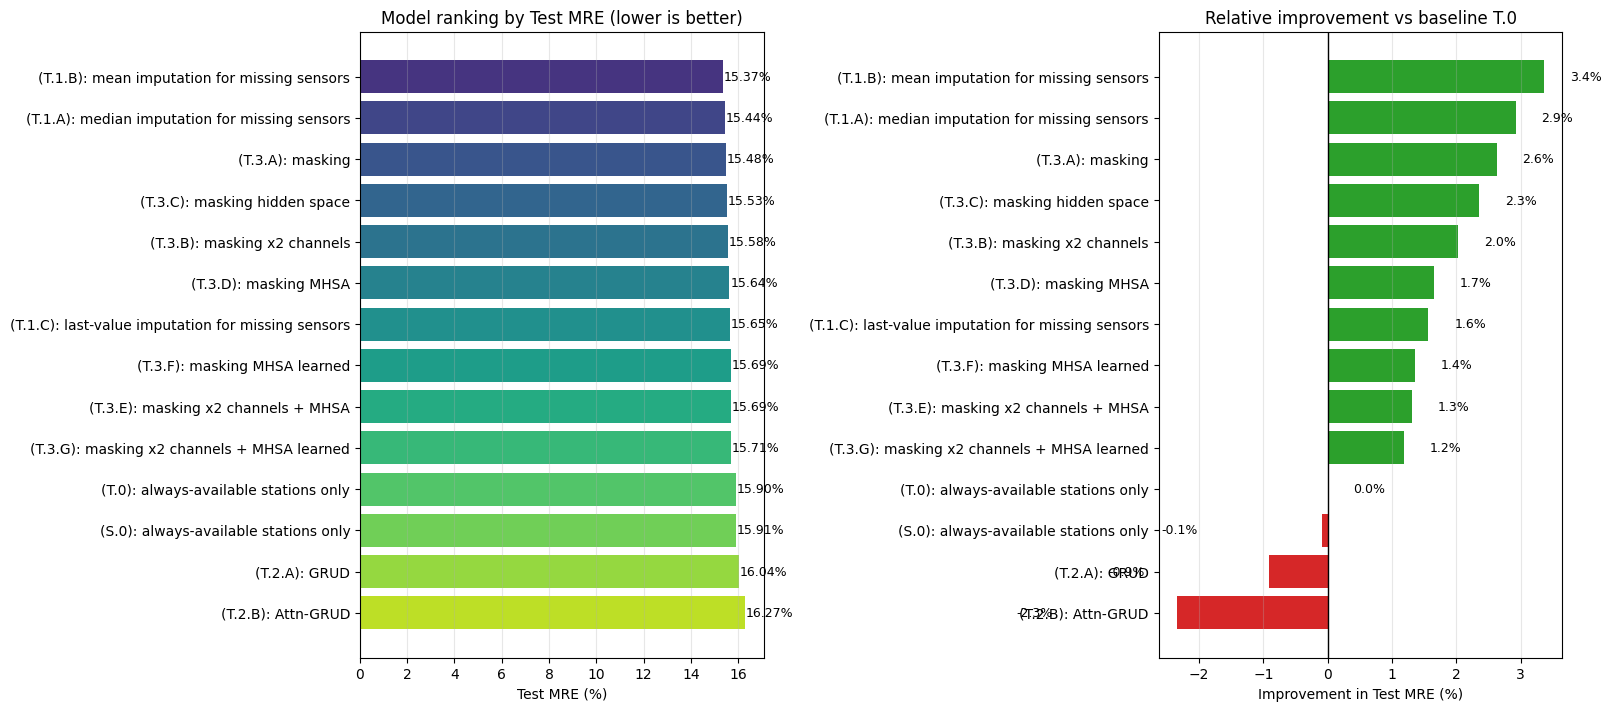

## Run3: high fidelity sensors, less time, bigger net

ds = dfs.read(time = slice("2022-01-01", "2023-10-30"))

high_fidelity = ["Dover", "ZeebruggeWielingendok", "NWA", "K141"]

In [ ]:
ERRORS = []

# DataManager
LAGS = 48

TRAIN_SIZE = 0.8        # percentage of data used for training 
VAL_SIZE = 0.1          # percentage of data used for validation
TEST_SIZE = 0.1         # percentage of data used for testing

COMPRESS_H = 12         # modes kept for H (surface elevation)
COMPRESS_U = 40         # modes kept for U (U velocity)
COMPRESS_V = 68         # modes kept for V (V velocity)

# Training
OPTIMIZER = "AdamW"     # optimizer to use
LEARNING_RATE = 1e-3    # learning rate for training
NUM_EPOCHS = 300        # maximum number of epochs for training
LR_SCHEDULER = "CosineAnnealingLR"      # learning rate scheduler to use
SCHEDULER_STEP_SIZE = NUM_EPOCHS        # step size for learning rate scheduler (if applicable)

BATCH_SIZE = 32         # batch size for training
PATIENCE = 60           # number of epochs with no improvement on validation loss before stopping training
VERBOSE_TRAIN = True

# Architecture
ENCODER_DEPTH = 3              # number of encoder layers
HIDDEN_SIZE = 32                # hidden size for encoder and decoder layers
N_HEADS = 4                     # number of attention heads (if using a transformer-based architecture)
DIM_FEEDFORWARD = 64            # dimension of feedforward network in transformer (if using a transformer-based architecture)
DECODER = "mlp"                 # type of decoder to use (mpl or cnn)   
DECODER_HIDDEN_SIZES = [64]     # hidden sizes for decoder layers 
DROPOUT = 0.0                   # dropout rate for encoder and decoder layers
MASKING_TYPE = "mask_data"      # type of masking to apply to inputs during training (mask_data, mask_data_random, etc.)

<div>
<style scoped>
    .dataframe tbody tr th:only-of-type {
        vertical-align: middle;
    }

    .dataframe tbody tr th {
        vertical-align: top;
    }

    .dataframe thead th {
        text-align: right;
    }
</style>
<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>model</th>
      <th>type</th>
      <th>train-mse</th>
      <th>val-mse</th>
      <th>test-mse</th>
      <th>train-mre</th>
      <th>val-mre</th>
      <th>test-mre</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>13</th>
      <td>(mSHRED): TR+mlp</td>
      <td>(T.3.G): masking x2 channels + MHSA learned</td>
      <td>0.003860</td>
      <td>0.004117</td>
      <td>0.006882</td>
      <td>0.124111</td>
      <td>0.125730</td>
      <td>0.153591</td>
    </tr>
    <tr>
      <th>3</th>
      <td>(mSHRED): TR+mlp</td>
      <td>(T.1.B): mean imputation for missing sensors</td>
      <td>0.003794</td>
      <td>0.004119</td>
      <td>0.006961</td>
      <td>0.123614</td>
      <td>0.126335</td>
      <td>0.154873</td>
    </tr>
    <tr>
      <th>7</th>
      <td>(mSHRED): TR+mlp</td>
      <td>(T.3.A): masking</td>
      <td>0.003404</td>
      <td>0.004168</td>
      <td>0.007124</td>
      <td>0.117961</td>
      <td>0.126487</td>
      <td>0.155623</td>
    </tr>
    <tr>
      <th>8</th>
      <td>(mSHRED): TR+mlp</td>
      <td>(T.3.B): masking x2 channels</td>
      <td>0.004157</td>
      <td>0.004119</td>
      <td>0.007047</td>
      <td>0.129386</td>
      <td>0.126258</td>
      <td>0.155804</td>
    </tr>
    <tr>
      <th>9</th>
      <td>(mSHRED): TR+mlp</td>
      <td>(T.3.C): masking hidden space</td>
      <td>0.004030</td>
      <td>0.004168</td>
      <td>0.007022</td>
      <td>0.126989</td>
      <td>0.126964</td>
      <td>0.155812</td>
    </tr>
    <tr>
      <th>4</th>
      <td>(mSHRED): TR+mlp</td>
      <td>(T.1.C): last-value imputation for missing sen...</td>
      <td>0.003623</td>
      <td>0.004150</td>
      <td>0.007124</td>
      <td>0.121129</td>
      <td>0.126490</td>
      <td>0.156346</td>
    </tr>
    <tr>
      <th>2</th>
      <td>(mSHRED): TR+mlp</td>
      <td>(T.1.A): median imputation for missing sensors</td>
      <td>0.003990</td>
      <td>0.004174</td>
      <td>0.007070</td>
      <td>0.126515</td>
      <td>0.127118</td>
      <td>0.156386</td>
    </tr>
    <tr>
      <th>12</th>
      <td>(mSHRED): TR+mlp</td>
      <td>(T.3.F): masking MHSA learned</td>
      <td>0.003986</td>
      <td>0.004166</td>
      <td>0.007077</td>
      <td>0.126487</td>
      <td>0.127070</td>
      <td>0.156671</td>
    </tr>
    <tr>
      <th>11</th>
      <td>(mSHRED): TR+mlp</td>
      <td>(T.3.E): masking x2 channels + MHSA</td>
      <td>0.003731</td>
      <td>0.004173</td>
      <td>0.007218</td>
      <td>0.123036</td>
      <td>0.127356</td>
      <td>0.157877</td>
    </tr>
    <tr>
      <th>10</th>
      <td>(mSHRED): TR+mlp</td>
      <td>(T.3.D): masking MHSA</td>
      <td>0.003739</td>
      <td>0.004181</td>
      <td>0.007218</td>
      <td>0.123203</td>
      <td>0.127263</td>
      <td>0.158070</td>
    </tr>
    <tr>
      <th>0</th>
      <td>(mSHRED): TR+mlp</td>
      <td>(T.0): always-available stations only</td>
      <td>0.004127</td>
      <td>0.004226</td>
      <td>0.007310</td>
      <td>0.128106</td>
      <td>0.127623</td>
      <td>0.158473</td>
    </tr>
    <tr>
      <th>1</th>
      <td>(mSHRED): LSTM+mlp</td>
      <td>(S.0): always-available stations only</td>
      <td>0.004210</td>
      <td>0.004186</td>
      <td>0.007369</td>
      <td>0.129524</td>
      <td>0.126976</td>
      <td>0.159171</td>
    </tr>
    <tr>
      <th>5</th>
      <td>(mSHRED): GRUD+mlp</td>
      <td>(T.2.A): GRUD</td>
      <td>0.004310</td>
      <td>0.004441</td>
      <td>0.007382</td>
      <td>0.131282</td>
      <td>0.131952</td>
      <td>0.160425</td>
    </tr>
    <tr>
      <th>6</th>
      <td>(mSHRED): Attn-GRUD+mlp</td>
      <td>(T.2.B): Attn-GRUD</td>
      <td>0.004145</td>
      <td>0.004424</td>
      <td>0.007327</td>
      <td>0.129031</td>
      <td>0.131267</td>
      <td>0.160446</td>
    </tr>
  </tbody>
</table>
</div>

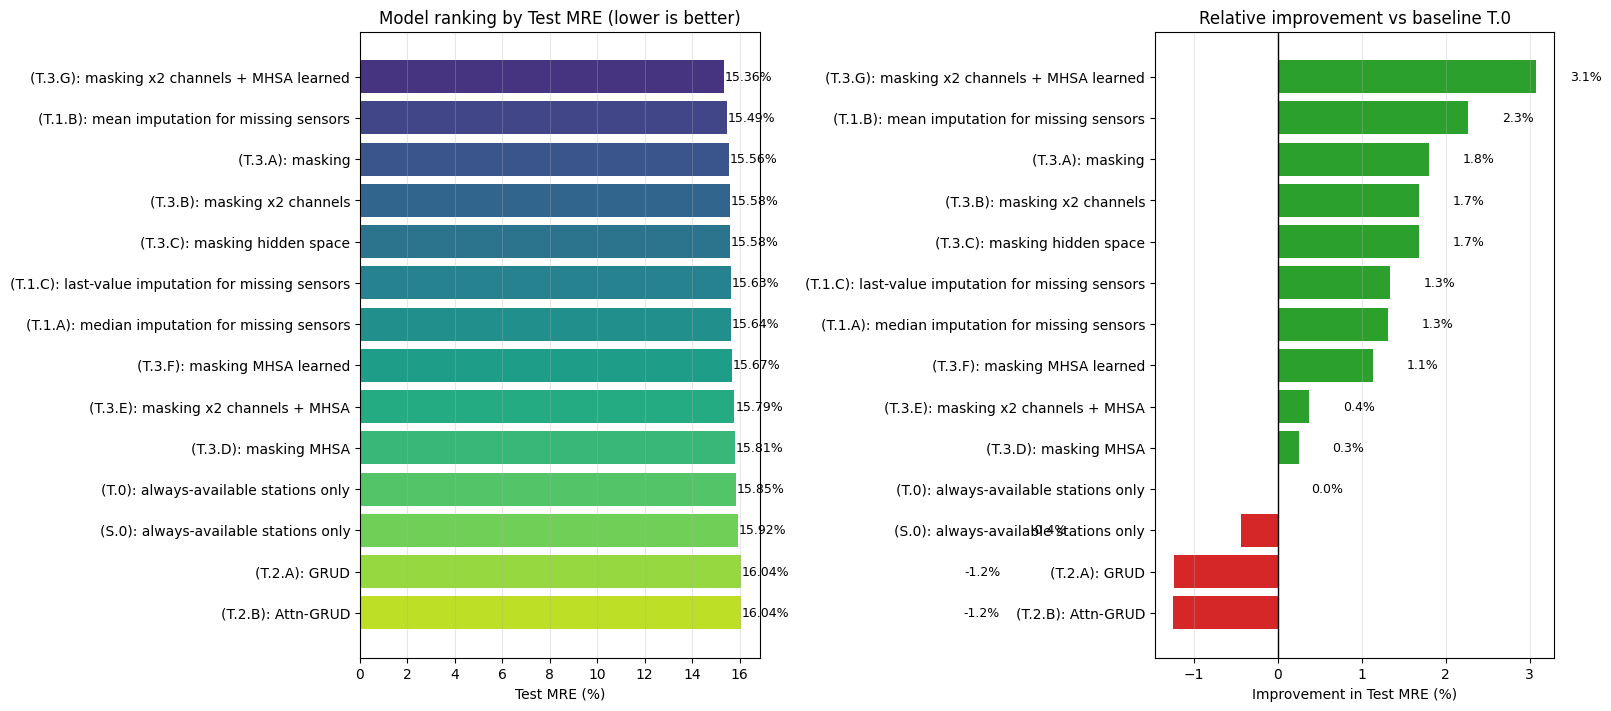

## Run4: high fidelity sensors, less time, biggest net

ds = dfs.read(time = slice("2022-01-01", "2023-10-30"))

high_fidelity = ["Dover", "ZeebruggeWielingendok", "NWA", "K141"]

In [ ]:
ERRORS = []

# DataManager
LAGS = 48

TRAIN_SIZE = 0.8        # percentage of data used for training 
VAL_SIZE = 0.1          # percentage of data used for validation
TEST_SIZE = 0.1         # percentage of data used for testing

COMPRESS_H = 12         # modes kept for H (surface elevation)
COMPRESS_U = 40         # modes kept for U (U velocity)
COMPRESS_V = 68         # modes kept for V (V velocity)

# Training
OPTIMIZER = "AdamW"     # optimizer to use
LEARNING_RATE = 1e-3    # learning rate for training
NUM_EPOCHS = 300        # maximum number of epochs for training
LR_SCHEDULER = "CosineAnnealingLR"      # learning rate scheduler to use
SCHEDULER_STEP_SIZE = NUM_EPOCHS        # step size for learning rate scheduler (if applicable)

BATCH_SIZE = 32         # batch size for training
PATIENCE = 60           # number of epochs with no improvement on validation loss before stopping training
VERBOSE_TRAIN = True

# Architecture
ENCODER_DEPTH = 3              # number of encoder layers
HIDDEN_SIZE = 64                # hidden size for encoder and decoder layers
N_HEADS = 4                     # number of attention heads (if using a transformer-based architecture)
DIM_FEEDFORWARD = 96            # dimension of feedforward network in transformer (if using a transformer-based architecture)
DECODER = "cnn"                 # type of decoder to use (mpl or cnn)   
DECODER_HIDDEN_SIZES = [100]     # hidden sizes for decoder layers 
DROPOUT = 0.0                   # dropout rate for encoder and decoder layers
MASKING_TYPE = "mask_data"      # type of masking to apply to inputs during training (mask_data, mask_data_random, etc.)

<div>
<style scoped>
    .dataframe tbody tr th:only-of-type {
        vertical-align: middle;
    }

    .dataframe tbody tr th {
        vertical-align: top;
    }

    .dataframe thead th {
        text-align: right;
    }
</style>
<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>model</th>
      <th>type</th>
      <th>train-mse</th>
      <th>val-mse</th>
      <th>test-mse</th>
      <th>train-mre</th>
      <th>val-mre</th>
      <th>test-mre</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>10</th>
      <td>(mSHRED): TR+cnn</td>
      <td>(T.3.D): masking MHSA</td>
      <td>0.003733</td>
      <td>0.004246</td>
      <td>0.007029</td>
      <td>0.122773</td>
      <td>0.128305</td>
      <td>0.155540</td>
    </tr>
    <tr>
      <th>2</th>
      <td>(mSHRED): TR+cnn</td>
      <td>(T.1.A): median imputation for missing sensors</td>
      <td>0.003652</td>
      <td>0.004158</td>
      <td>0.007098</td>
      <td>0.121595</td>
      <td>0.126725</td>
      <td>0.155994</td>
    </tr>
    <tr>
      <th>13</th>
      <td>(mSHRED): TR+cnn</td>
      <td>(T.3.G): masking x2 channels + MHSA learned</td>
      <td>0.003882</td>
      <td>0.004139</td>
      <td>0.006999</td>
      <td>0.125136</td>
      <td>0.126668</td>
      <td>0.156000</td>
    </tr>
    <tr>
      <th>8</th>
      <td>(mSHRED): TR+cnn</td>
      <td>(T.3.B): masking x2 channels</td>
      <td>0.004048</td>
      <td>0.004189</td>
      <td>0.007052</td>
      <td>0.127719</td>
      <td>0.127617</td>
      <td>0.156077</td>
    </tr>
    <tr>
      <th>4</th>
      <td>(mSHRED): TR+cnn</td>
      <td>(T.1.C): last-value imputation for missing sen...</td>
      <td>0.003608</td>
      <td>0.004157</td>
      <td>0.007117</td>
      <td>0.121004</td>
      <td>0.127218</td>
      <td>0.156219</td>
    </tr>
    <tr>
      <th>7</th>
      <td>(mSHRED): TR+cnn</td>
      <td>(T.3.A): masking</td>
      <td>0.003755</td>
      <td>0.004161</td>
      <td>0.007108</td>
      <td>0.123269</td>
      <td>0.126888</td>
      <td>0.156675</td>
    </tr>
    <tr>
      <th>12</th>
      <td>(mSHRED): TR+cnn</td>
      <td>(T.3.F): masking MHSA learned</td>
      <td>0.003470</td>
      <td>0.004147</td>
      <td>0.007150</td>
      <td>0.119185</td>
      <td>0.126592</td>
      <td>0.156695</td>
    </tr>
    <tr>
      <th>3</th>
      <td>(mSHRED): TR+cnn</td>
      <td>(T.1.B): mean imputation for missing sensors</td>
      <td>0.003350</td>
      <td>0.004184</td>
      <td>0.007254</td>
      <td>0.117683</td>
      <td>0.127470</td>
      <td>0.157595</td>
    </tr>
    <tr>
      <th>11</th>
      <td>(mSHRED): TR+cnn</td>
      <td>(T.3.E): masking x2 channels + MHSA</td>
      <td>0.004118</td>
      <td>0.004234</td>
      <td>0.007218</td>
      <td>0.128513</td>
      <td>0.128364</td>
      <td>0.158961</td>
    </tr>
    <tr>
      <th>9</th>
      <td>(mSHRED): TR+cnn</td>
      <td>(T.3.C): masking hidden space</td>
      <td>0.003863</td>
      <td>0.004233</td>
      <td>0.007254</td>
      <td>0.125150</td>
      <td>0.128364</td>
      <td>0.159929</td>
    </tr>
    <tr>
      <th>1</th>
      <td>(mSHRED): LSTM+cnn</td>
      <td>(S.0): always-available stations only</td>
      <td>0.004137</td>
      <td>0.004234</td>
      <td>0.007423</td>
      <td>0.128490</td>
      <td>0.127782</td>
      <td>0.160043</td>
    </tr>
    <tr>
      <th>0</th>
      <td>(mSHRED): TR+cnn</td>
      <td>(T.0): always-available stations only</td>
      <td>0.003916</td>
      <td>0.004286</td>
      <td>0.007451</td>
      <td>0.125666</td>
      <td>0.128541</td>
      <td>0.160292</td>
    </tr>
    <tr>
      <th>5</th>
      <td>(mSHRED): GRUD+cnn</td>
      <td>(T.2.A): GRUD</td>
      <td>0.004621</td>
      <td>0.004756</td>
      <td>0.007426</td>
      <td>0.135988</td>
      <td>0.137019</td>
      <td>0.162062</td>
    </tr>
    <tr>
      <th>6</th>
      <td>(mSHRED): Attn-GRUD+cnn</td>
      <td>(T.2.B): Attn-GRUD</td>
      <td>0.003499</td>
      <td>0.004574</td>
      <td>0.007687</td>
      <td>0.119904</td>
      <td>0.132847</td>
      <td>0.163792</td>
    </tr>
  </tbody>
</table>
</div>

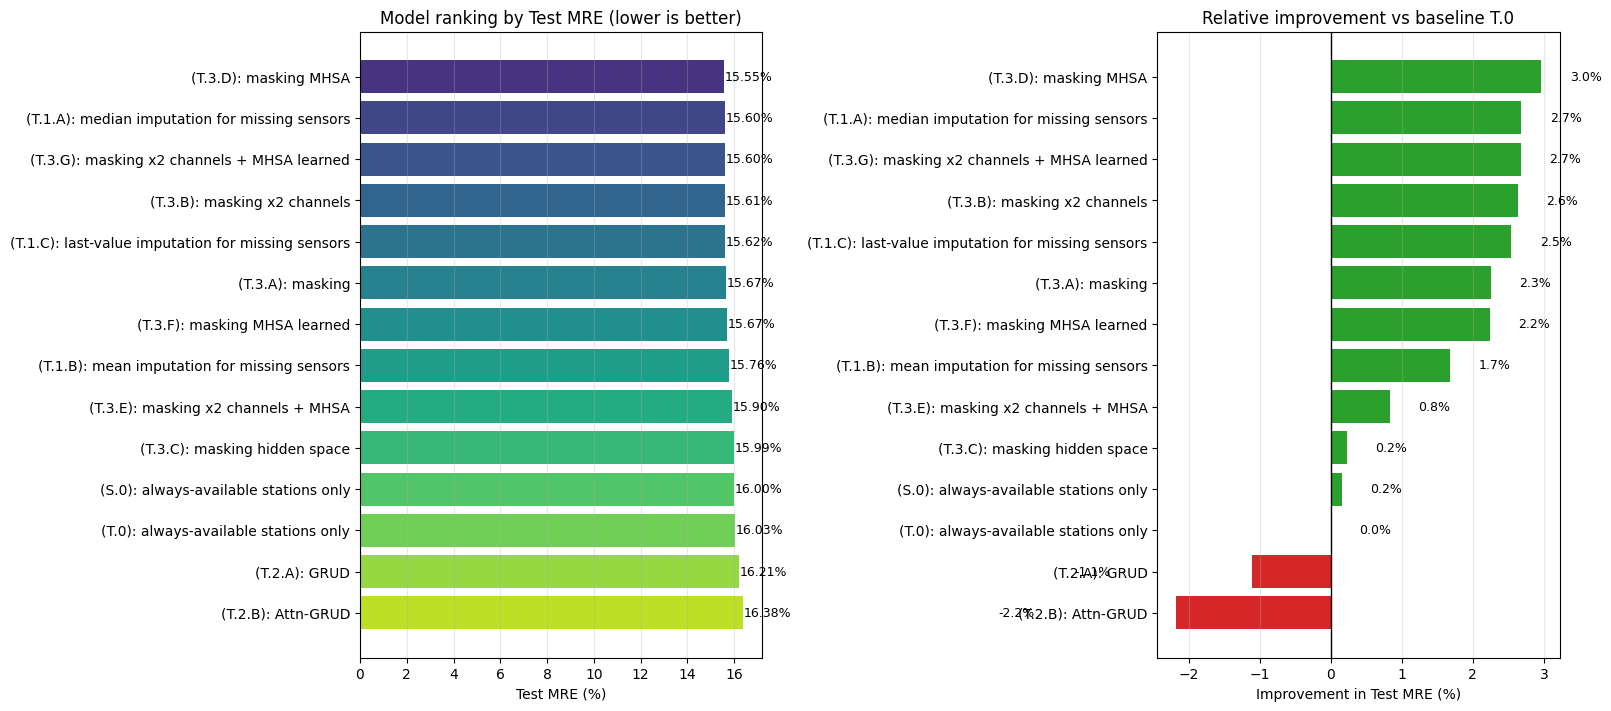

## Run 5: high fidelity sensors, less time, smaller lags

ds = dfs.read(time = slice("2022-01-01", "2023-10-30"))

high_fidelity = ["Dover", "ZeebruggeWielingendok", "NWA", "K141"]

In [ ]:
ERRORS = []

# DataManager
LAGS = 24

TRAIN_SIZE = 0.8        # percentage of data used for training 
VAL_SIZE = 0.1          # percentage of data used for validation
TEST_SIZE = 0.1         # percentage of data used for testing

COMPRESS_H = 12         # modes kept for H (surface elevation)
COMPRESS_U = 40         # modes kept for U (U velocity)
COMPRESS_V = 68         # modes kept for V (V velocity)

# Training
OPTIMIZER = "AdamW"     # optimizer to use
LEARNING_RATE = 1e-3    # learning rate for training
NUM_EPOCHS = 200        # maximum number of epochs for training
LR_SCHEDULER = "CosineAnnealingLR"      # learning rate scheduler to use
SCHEDULER_STEP_SIZE = NUM_EPOCHS        # step size for learning rate scheduler (if applicable)

BATCH_SIZE = 32         # batch size for training
PATIENCE = 50           # number of epochs with no improvement on validation loss before stopping training
VERBOSE_TRAIN = True

# Architecture
ENCODER_DEPTH = 3              # number of encoder layers
HIDDEN_SIZE = 64                # hidden size for encoder and decoder layers
N_HEADS = 4                     # number of attention heads (if using a transformer-based architecture)
DIM_FEEDFORWARD = 96            # dimension of feedforward network in transformer (if using a transformer-based architecture)
DECODER = "cnn"                 # type of decoder to use (mpl or cnn)   
DECODER_HIDDEN_SIZES = [100]     # hidden sizes for decoder layers 
DROPOUT = 0.0                   # dropout rate for encoder and decoder layers
MASKING_TYPE = "mask_data"      # type of masking to apply to inputs during training (mask_data, mask_data_random, etc.)

<div>
<style scoped>
    .dataframe tbody tr th:only-of-type {
        vertical-align: middle;
    }

    .dataframe tbody tr th {
        vertical-align: top;
    }

    .dataframe thead th {
        text-align: right;
    }
</style>
<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>model</th>
      <th>type</th>
      <th>train-mse</th>
      <th>val-mse</th>
      <th>test-mse</th>
      <th>train-mre</th>
      <th>val-mre</th>
      <th>test-mre</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>13</th>
      <td>(mSHRED): TR+cnn</td>
      <td>(T.3.G): masking x2 channels + MHSA learned</td>
      <td>0.003921</td>
      <td>0.004178</td>
      <td>0.007104</td>
      <td>0.125972</td>
      <td>0.127530</td>
      <td>0.157272</td>
    </tr>
    <tr>
      <th>9</th>
      <td>(mSHRED): TR+cnn</td>
      <td>(T.3.C): masking hidden space</td>
      <td>0.003767</td>
      <td>0.004241</td>
      <td>0.007210</td>
      <td>0.123935</td>
      <td>0.128384</td>
      <td>0.157276</td>
    </tr>
    <tr>
      <th>11</th>
      <td>(mSHRED): TR+cnn</td>
      <td>(T.3.E): masking x2 channels + MHSA</td>
      <td>0.003838</td>
      <td>0.004269</td>
      <td>0.007193</td>
      <td>0.124595</td>
      <td>0.128501</td>
      <td>0.157703</td>
    </tr>
    <tr>
      <th>7</th>
      <td>(mSHRED): TR+cnn</td>
      <td>(T.3.A): masking</td>
      <td>0.003938</td>
      <td>0.004235</td>
      <td>0.007164</td>
      <td>0.125906</td>
      <td>0.128442</td>
      <td>0.157728</td>
    </tr>
    <tr>
      <th>4</th>
      <td>(mSHRED): TR+cnn</td>
      <td>(T.1.C): last-value imputation for missing sen...</td>
      <td>0.003855</td>
      <td>0.004217</td>
      <td>0.007184</td>
      <td>0.125139</td>
      <td>0.128133</td>
      <td>0.157769</td>
    </tr>
    <tr>
      <th>10</th>
      <td>(mSHRED): TR+cnn</td>
      <td>(T.3.D): masking MHSA</td>
      <td>0.003976</td>
      <td>0.004252</td>
      <td>0.007183</td>
      <td>0.126534</td>
      <td>0.128824</td>
      <td>0.157849</td>
    </tr>
    <tr>
      <th>12</th>
      <td>(mSHRED): TR+cnn</td>
      <td>(T.3.F): masking MHSA learned</td>
      <td>0.003419</td>
      <td>0.004274</td>
      <td>0.007238</td>
      <td>0.118639</td>
      <td>0.128742</td>
      <td>0.158148</td>
    </tr>
    <tr>
      <th>2</th>
      <td>(mSHRED): TR+cnn</td>
      <td>(T.1.A): median imputation for missing sensors</td>
      <td>0.004126</td>
      <td>0.004194</td>
      <td>0.007247</td>
      <td>0.128822</td>
      <td>0.127495</td>
      <td>0.159000</td>
    </tr>
    <tr>
      <th>8</th>
      <td>(mSHRED): TR+cnn</td>
      <td>(T.3.B): masking x2 channels</td>
      <td>0.003888</td>
      <td>0.004279</td>
      <td>0.007270</td>
      <td>0.125614</td>
      <td>0.129427</td>
      <td>0.159761</td>
    </tr>
    <tr>
      <th>3</th>
      <td>(mSHRED): TR+cnn</td>
      <td>(T.1.B): mean imputation for missing sensors</td>
      <td>0.003296</td>
      <td>0.004258</td>
      <td>0.007485</td>
      <td>0.117211</td>
      <td>0.128284</td>
      <td>0.160714</td>
    </tr>
    <tr>
      <th>5</th>
      <td>(mSHRED): GRUD+cnn</td>
      <td>(T.2.A): GRUD</td>
      <td>0.004361</td>
      <td>0.004638</td>
      <td>0.007400</td>
      <td>0.132184</td>
      <td>0.134450</td>
      <td>0.161763</td>
    </tr>
    <tr>
      <th>1</th>
      <td>(mSHRED): LSTM+cnn</td>
      <td>(S.0): always-available stations only</td>
      <td>0.004460</td>
      <td>0.004313</td>
      <td>0.007557</td>
      <td>0.133100</td>
      <td>0.128951</td>
      <td>0.161863</td>
    </tr>
    <tr>
      <th>6</th>
      <td>(mSHRED): Attn-GRUD+cnn</td>
      <td>(T.2.B): Attn-GRUD</td>
      <td>0.004622</td>
      <td>0.004658</td>
      <td>0.007456</td>
      <td>0.135776</td>
      <td>0.135334</td>
      <td>0.162120</td>
    </tr>
    <tr>
      <th>0</th>
      <td>(mSHRED): TR+cnn</td>
      <td>(T.0): always-available stations only</td>
      <td>0.004410</td>
      <td>0.004355</td>
      <td>0.007585</td>
      <td>0.132330</td>
      <td>0.130037</td>
      <td>0.162433</td>
    </tr>
  </tbody>
</table>
</div>

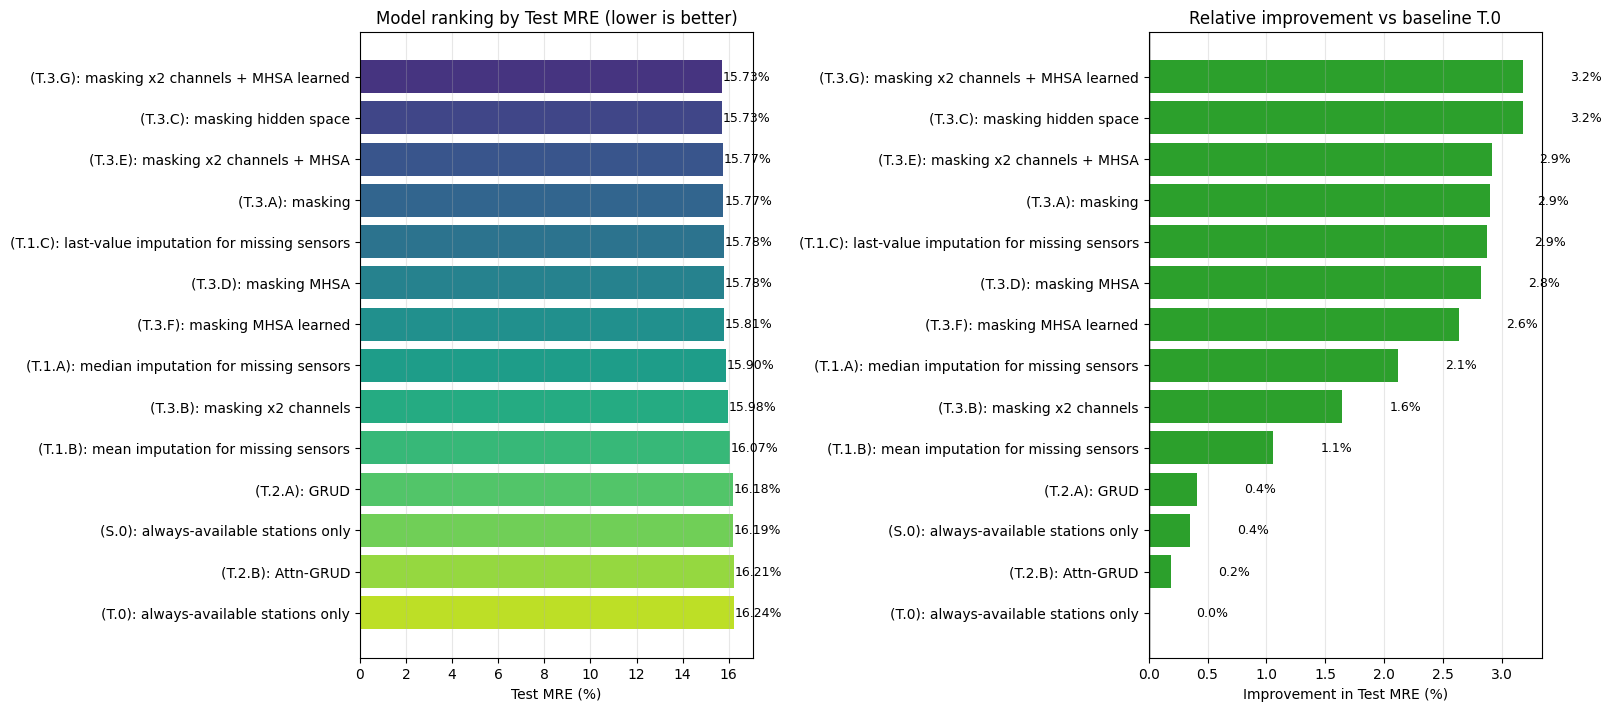

## Run 6: high fidelity sensors, less time, smaller net

In [ ]:
ERRORS = []

# DataManager
LAGS = 24

TRAIN_SIZE = 0.8        # percentage of data used for training 
VAL_SIZE = 0.1          # percentage of data used for validation
TEST_SIZE = 0.1         # percentage of data used for testing

COMPRESS_H = 12         # modes kept for H (surface elevation)
COMPRESS_U = 40         # modes kept for U (U velocity)
COMPRESS_V = 68         # modes kept for V (V velocity)

# Training
OPTIMIZER = "AdamW"     # optimizer to use
LEARNING_RATE = 1e-3    # learning rate for training
NUM_EPOCHS = 200        # maximum number of epochs for training
LR_SCHEDULER = "CosineAnnealingLR"      # learning rate scheduler to use
SCHEDULER_STEP_SIZE = NUM_EPOCHS        # step size for learning rate scheduler (if applicable)

BATCH_SIZE = 32         # batch size for training
PATIENCE = 40           # number of epochs with no improvement on validation loss before stopping training
VERBOSE_TRAIN = True

# Architecture
ENCODER_DEPTH = 2              # number of encoder layers
HIDDEN_SIZE = 32                # hidden size for encoder and decoder layers
N_HEADS = 4                     # number of attention heads (if using a transformer-based architecture)
DIM_FEEDFORWARD = 48            # dimension of feedforward network in transformer (if using a transformer-based architecture)
DECODER = "cnn"                 # type of decoder to use (mpl or cnn)   
DECODER_HIDDEN_SIZES = [64]     # hidden sizes for decoder layers 
DROPOUT = 0.0                   # dropout rate for encoder and decoder layers
MASKING_TYPE = "mask_data"      # type of masking to apply to inputs during training (mask_data, mask_data_random, etc.)

<div>
<style scoped>
    .dataframe tbody tr th:only-of-type {
        vertical-align: middle;
    }

    .dataframe tbody tr th {
        vertical-align: top;
    }

    .dataframe thead th {
        text-align: right;
    }
</style>
<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>model</th>
      <th>type</th>
      <th>train-mse</th>
      <th>val-mse</th>
      <th>test-mse</th>
      <th>train-mre</th>
      <th>val-mre</th>
      <th>test-mre</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>7</th>
      <td>(mSHRED): TR+cnn</td>
      <td>(T.3.A): masking</td>
      <td>0.003760</td>
      <td>0.004203</td>
      <td>0.007088</td>
      <td>0.122991</td>
      <td>0.127405</td>
      <td>0.155964</td>
    </tr>
    <tr>
      <th>2</th>
      <td>(mSHRED): TR+cnn</td>
      <td>(T.1.A): median imputation for missing sensors</td>
      <td>0.003857</td>
      <td>0.004191</td>
      <td>0.007029</td>
      <td>0.124478</td>
      <td>0.127571</td>
      <td>0.155997</td>
    </tr>
    <tr>
      <th>8</th>
      <td>(mSHRED): TR+cnn</td>
      <td>(T.3.B): masking x2 channels</td>
      <td>0.003950</td>
      <td>0.004202</td>
      <td>0.007058</td>
      <td>0.125874</td>
      <td>0.127704</td>
      <td>0.156410</td>
    </tr>
    <tr>
      <th>3</th>
      <td>(mSHRED): TR+cnn</td>
      <td>(T.1.B): mean imputation for missing sensors</td>
      <td>0.003940</td>
      <td>0.004149</td>
      <td>0.007075</td>
      <td>0.125818</td>
      <td>0.126834</td>
      <td>0.156727</td>
    </tr>
    <tr>
      <th>13</th>
      <td>(mSHRED): TR+cnn</td>
      <td>(T.3.G): masking x2 channels + MHSA learned</td>
      <td>0.004201</td>
      <td>0.004211</td>
      <td>0.007104</td>
      <td>0.129420</td>
      <td>0.127693</td>
      <td>0.156799</td>
    </tr>
    <tr>
      <th>4</th>
      <td>(mSHRED): TR+cnn</td>
      <td>(T.1.C): last-value imputation for missing sen...</td>
      <td>0.003820</td>
      <td>0.004193</td>
      <td>0.007116</td>
      <td>0.124354</td>
      <td>0.127497</td>
      <td>0.157123</td>
    </tr>
    <tr>
      <th>9</th>
      <td>(mSHRED): TR+cnn</td>
      <td>(T.3.C): masking hidden space</td>
      <td>0.004034</td>
      <td>0.004223</td>
      <td>0.007079</td>
      <td>0.127455</td>
      <td>0.128228</td>
      <td>0.157338</td>
    </tr>
    <tr>
      <th>10</th>
      <td>(mSHRED): TR+cnn</td>
      <td>(T.3.D): masking MHSA</td>
      <td>0.003720</td>
      <td>0.004216</td>
      <td>0.007172</td>
      <td>0.122715</td>
      <td>0.127928</td>
      <td>0.157939</td>
    </tr>
    <tr>
      <th>12</th>
      <td>(mSHRED): TR+cnn</td>
      <td>(T.3.F): masking MHSA learned</td>
      <td>0.004039</td>
      <td>0.004167</td>
      <td>0.007165</td>
      <td>0.127264</td>
      <td>0.127164</td>
      <td>0.158056</td>
    </tr>
    <tr>
      <th>11</th>
      <td>(mSHRED): TR+cnn</td>
      <td>(T.3.E): masking x2 channels + MHSA</td>
      <td>0.003663</td>
      <td>0.004206</td>
      <td>0.007307</td>
      <td>0.122258</td>
      <td>0.127746</td>
      <td>0.159447</td>
    </tr>
    <tr>
      <th>5</th>
      <td>(mSHRED): GRUD+cnn</td>
      <td>(T.2.A): GRUD</td>
      <td>0.004043</td>
      <td>0.004472</td>
      <td>0.007331</td>
      <td>0.127346</td>
      <td>0.131914</td>
      <td>0.159775</td>
    </tr>
    <tr>
      <th>1</th>
      <td>(mSHRED): LSTM+cnn</td>
      <td>(S.0): always-available stations only</td>
      <td>0.004278</td>
      <td>0.004280</td>
      <td>0.007521</td>
      <td>0.130158</td>
      <td>0.128371</td>
      <td>0.160711</td>
    </tr>
    <tr>
      <th>0</th>
      <td>(mSHRED): TR+cnn</td>
      <td>(T.0): always-available stations only</td>
      <td>0.004344</td>
      <td>0.004342</td>
      <td>0.007507</td>
      <td>0.131373</td>
      <td>0.129488</td>
      <td>0.161270</td>
    </tr>
    <tr>
      <th>6</th>
      <td>(mSHRED): Attn-GRUD+cnn</td>
      <td>(T.2.B): Attn-GRUD</td>
      <td>0.004613</td>
      <td>0.004933</td>
      <td>0.007494</td>
      <td>0.136013</td>
      <td>0.139342</td>
      <td>0.163372</td>
    </tr>
  </tbody>
</table>
</div>

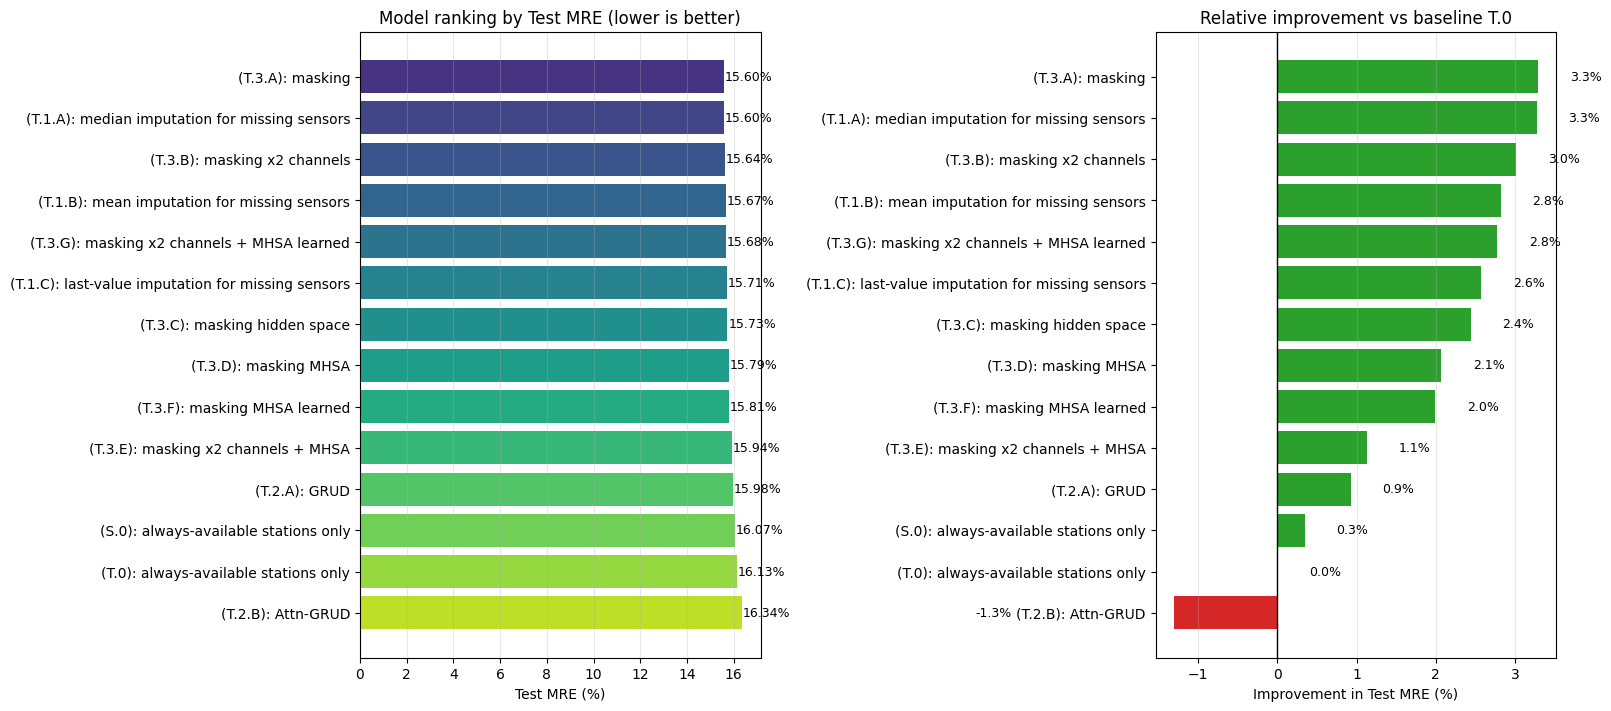